# Fundación YPF - Data Science
## Entrega Final: Predicción de la Tasa de Promoción Escolar en el Nivel Secundario (Regresión y Clasificación)

**Alumnas:** Florencia Zoni, Virginia Contreras  
**Curso:** Data Science - Fundación YPF

---

## 1. Introducción y Contexto
En la gestión educativa, el seguimiento de las trayectorias escolares es clave para evaluar la estabilidad del sistema. La **tasa de promoción efectiva** mide el porcentaje de estudiantes que aprueban y pasan de año de forma regular.

Trabajamos con la base `Tasa_de_Promocion_Efectiva_2012-2023_unificada.xlsx` (información oficial por jurisdicción y año, **unidad de análisis: provincia-año**, 2012-2023).

### Objetivos
Aplicar **Aprendizaje Supervisado** de punta a punta (AED → modelado → evaluación → selección), controlando el *overfitting* mediante optimización de hiperparámetros y validación cruzada temporal:

1. **Regresión:** predecir el *valor* de la tasa de promoción total de secundaria del año siguiente ($t+1$) a partir de las tasas del año actual ($t$).
2. **Clasificación:** predecir si la tasa del año siguiente **sube o no sube** respecto de la actual.

## 2. Estrategia Metodológica
1. **Carga y limpieza:** eliminación de agregados que duplican información y de columnas con nulos estructurales.
2. **AED:** distribución, evolución temporal, comparación entre provincias y correlaciones.
3. **Target:** variable $t+1$ (por jurisdicción) y su versión binaria.
4. **Partición temporal:** *train* 2012-2018 / *test* 2019-2022 (los años de test incluyen el impacto de la pandemia).
5. **Modelos:** baselines + modelos lineales + Random Forest, tanto para regresión como para clasificación.
6. **Optimización y validación:** `GridSearchCV` con validación cruzada temporal (siempre se entrena con el pasado y se valida con el futuro).
7. **Evaluación y selección:** métricas en *train* vs *test* para detectar *overfitting*, y elección fundamentada del mejor modelo.

## 3. Carga y Limpieza de Datos
### 3.1. Librerías y carga

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42

# En Google Colab: si el archivo no está en el entorno, se solicita la carga manual
ruta_archivo = 'Tasa_de_Promocion_Efectiva_2012-2023_unificada.xlsx'
if not os.path.exists(ruta_archivo):
    from google.colab import files
    print('Subí el archivo', ruta_archivo)
    files.upload()

df = pd.read_excel(ruta_archivo)
df.columns = df.columns.str.strip()
COL_PROV = 'División político-territorial'

print(f'Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head()

Dimensiones: 324 filas x 18 columnas


,Año,División político-territorial,Estructura educativa,Primaria - Total,Primaria - 1° Año,Primaria - 2° Año,Primaria - 3° Año,Primaria - 4° Año,Primaria - 5° Año,Primaria - 6° Año,Primaria - 7° Año,Secundaria - Total,Secundaria - 7° Año,Secundaria - 8° Año,Secundaria - 9° Año,Secundaria - 10° Año,Secundaria - 11° Año,Secundaria - 12° Año
0,2023,Buenos Aires,6-6,97.0422,100.6889,94.6829,95.3455,96.3991,96.7931,98.7196,NaN,87.0482,93.7906,89.2891,89.2842,81.5682,85.2882,80.8773
1,2023,Catamarca,6-6,98.8454,100.5482,99.5467,97.6836,99.0491,97.9604,98.3532,NaN,88.0095,93.3128,87.4566,86.7855,85.4326,92.1219,81.8006
2,2023,Chaco,7-5,97.7121,99.4323,98.8346,96.2084,98.2575,96.6791,97.0723,97.6521,77.2890,NaN,80.5473,76.4445,76.8003,78.6136,72.4957
3,2023,Chubut,6-6,99.6969,99.7519,99.7665,99.5723,99.2248,99.8922,99.9799,NaN,86.3467,90.4766,87.1913,86.4412,82.9968,84.3292,85.5093
4,2023,Ciudad de Buenos Aires,7-5,98.3077,98.8849,97.2360,97.5947,97.8824,97.5986,99.2355,99.7380,88.2758,NaN,98.5944,87.1759,86.8790,89.5332,78.0001


### 3.2. Valores nulos y jurisdicciones

In [2]:
nulos = df.isna().sum()
print('Columnas con nulos:')
print(nulos[nulos > 0])
print('\nJurisdicciones:', sorted(df[COL_PROV].unique()))

Columnas con nulos:
Estructura educativa     12
Primaria - 7° Año       168
Secundaria - 7° Año     144
dtype: int64

Jurisdicciones: ['Buenos Aires', 'Catamarca', 'Chaco', 'Chubut', 'Ciudad de Buenos Aires', 'Conurbano', 'Cordoba', 'Corrientes', 'Entre Rios', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquén', 'Resto de Bs As', 'Rio Negro', 'Salta', 'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fe', 'Santiago Del Estero', 'Tierra Del Fuego', 'Total País', 'Tucumán']


**Hallazgos:**
- `Primaria - 7° Año` solo existe en las jurisdicciones con estructura 7-5 y `Secundaria - 7° Año` solo en las de estructura 6-6. Son nulos **estructurales** (ese año de estudio no existe en la otra estructura), no datos perdidos al azar, por eso se eliminan esas dos columnas y se conserva la estructura como variable.
- `Estructura educativa` tiene nulos únicamente en `Total País`.
- La base mezcla **agregados** con provincias: `Total País` (suma de todo), `Conurbano` y `Resto de Bs As` (ya incluidos en `Buenos Aires`). Dejarlos duplicaría observaciones y sesgaría los modelos.

In [3]:
# Separamos Total País (se usa solo como referencia nacional en el AED)
df_pais = df[df[COL_PROV] == 'Total País'].copy()

# Base de trabajo: solo provincias/jurisdicciones sin solapamientos
excluir = ['Total País', 'Conurbano', 'Resto de Bs As']
df_prov = df[~df[COL_PROV].isin(excluir)].copy()

# Columnas con nulos estructurales
df_prov = df_prov.drop(columns=['Primaria - 7° Año', 'Secundaria - 7° Año'])

# Variable binaria para la estructura educativa (1 = 7-5, 0 = 6-6)
df_prov['Estructura_7-5'] = (df_prov['Estructura educativa'] == '7-5').astype(int)

df_prov = df_prov.sort_values([COL_PROV, 'Año']).reset_index(drop=True)

print(f'Jurisdicciones: {df_prov[COL_PROV].nunique()} | Años: {df_prov["Año"].min()}-{df_prov["Año"].max()}')
print(f'Observaciones: {len(df_prov)} | Nulos restantes: {int(df_prov.isna().sum().sum())}')

Jurisdicciones: 24 | Años: 2012-2023
Observaciones: 288 | Nulos restantes: 0


## 4. Análisis Exploratorio de Datos (AED)
### 4.1. Estadísticas descriptivas

In [4]:
cols_sec = ['Secundaria - Total', 'Secundaria - 8° Año', 'Secundaria - 9° Año',
            'Secundaria - 10° Año', 'Secundaria - 11° Año', 'Secundaria - 12° Año']
df_prov[cols_sec].describe().round(2)

,Secundaria - Total,Secundaria - 8° Año,Secundaria - 9° Año,Secundaria - 10° Año,Secundaria - 11° Año,Secundaria - 12° Año
count,288.00,288.00,288.00,288.00,288.00,288.00
mean,81.75,80.35,81.15,81.72,86.92,78.52
std,5.80,8.83,7.17,6.08,4.59,7.00
min,67.10,59.10,62.45,68.06,74.77,51.69
25%,77.82,73.90,76.44,77.68,83.98,74.78
50%,80.97,78.62,80.68,80.60,86.69,77.84
75%,85.25,87.17,84.98,84.75,89.53,83.30
max,97.81,101.06,101.06,100.47,101.23,96.53


### 4.2. Evolución temporal de la tasa de promoción

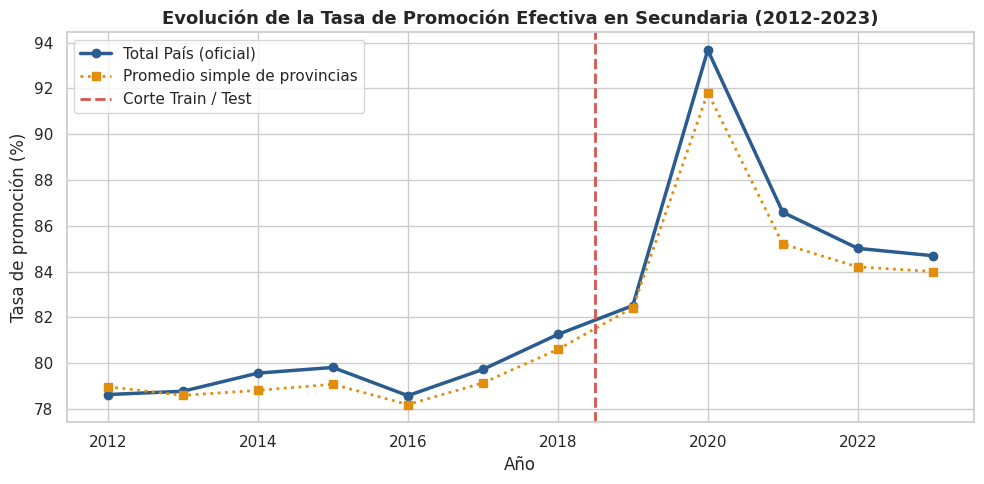

In [5]:
pais = df_pais.sort_values('Año').set_index('Año')['Secundaria - Total']
prom_prov = df_prov.groupby('Año')['Secundaria - Total'].mean()

plt.figure(figsize=(10, 5))
plt.plot(pais.index, pais.values, marker='o', color='#2b5c8f', linewidth=2.5, label='Total País (oficial)')
plt.plot(prom_prov.index, prom_prov.values, marker='s', color='#e08e0b', linewidth=2, linestyle=':', label='Promedio simple de provincias')
plt.axvline(x=2018.5, color='#d9534f', linestyle='--', linewidth=2, label='Corte Train / Test')
plt.title('Evolución de la Tasa de Promoción Efectiva en Secundaria (2012-2023)', fontsize=13, fontweight='bold')
plt.xlabel('Año'); plt.ylabel('Tasa de promoción (%)')
plt.legend(); plt.tight_layout(); plt.show()

**Lectura:** entre 2012 y 2018 la tasa nacional se mantuvo estable (≈ 78-81%). Después sube a 82,5% en 2019 y **salta a 93,7% en 2020**, por las flexibilizaciones de los criterios de promoción durante la pandemia. Luego baja (86,6% en 2021, 85,0% en 2022, 84,7% en 2023) pero se estabiliza **por encima del nivel previo**. Es decir, el *test* contiene un régimen distinto del que ve el modelo en *train*. El promedio simple de provincias acompaña bien la serie oficial.

### 4.3. Dispersión entre provincias por año

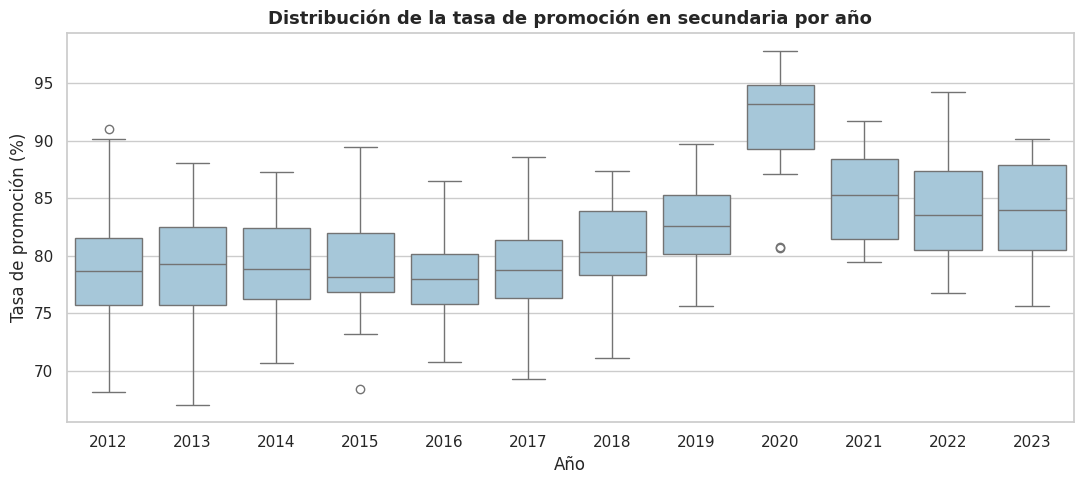

In [6]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=df_prov, x='Año', y='Secundaria - Total', color='#9ecae1')
plt.title('Distribución de la tasa de promoción en secundaria por año', fontsize=13, fontweight='bold')
plt.ylabel('Tasa de promoción (%)')
plt.tight_layout(); plt.show()

### 4.4. Evolución por año de estudio

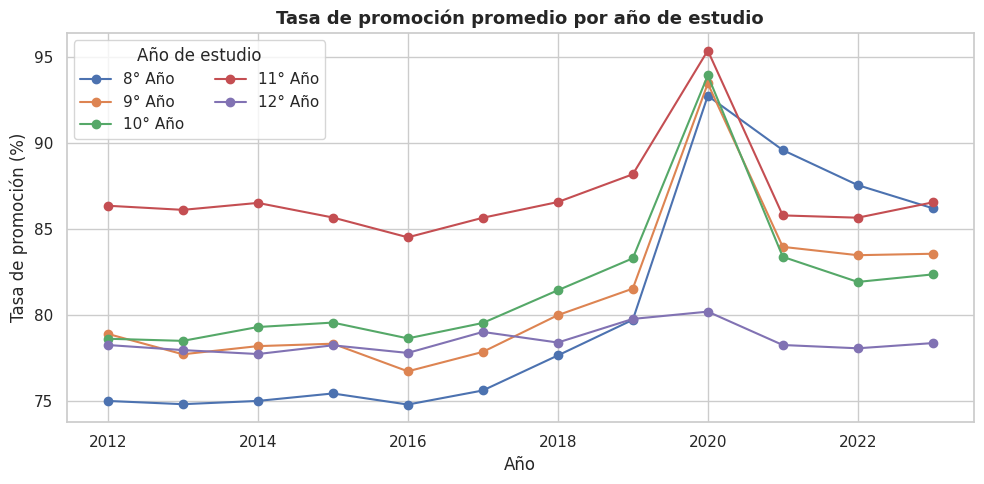

In [7]:
cols_anio = ['Secundaria - 8° Año', 'Secundaria - 9° Año', 'Secundaria - 10° Año',
             'Secundaria - 11° Año', 'Secundaria - 12° Año']
evol = df_prov.groupby('Año')[cols_anio].mean()

plt.figure(figsize=(10, 5))
for c in cols_anio:
    plt.plot(evol.index, evol[c], marker='o', label=c.replace('Secundaria - ', ''))
plt.title('Tasa de promoción promedio por año de estudio', fontsize=13, fontweight='bold')
plt.xlabel('Año'); plt.ylabel('Tasa de promoción (%)')
plt.legend(title='Año de estudio', ncol=2); plt.tight_layout(); plt.show()

**Lectura:** en 2020 subieron con fuerza los años 8° a 11° (por ejemplo 8° pasa de 79,7% a 92,7%), mientras que **12° año casi no se movió en toda la serie (≈ 78-80%)**: el último año conserva una exigencia estable. Después de 2020, 10° y 11° vuelven cerca de su nivel previo, pero 8° se mantiene alto (86,2% en 2023). El *boxplot* anterior también muestra que la dispersión entre provincias es similar en todos los años (desvío ≈ 4-5 p.p.): el salto de 2020 fue general, no de unas pocas provincias.

### 4.5. Ranking de jurisdicciones

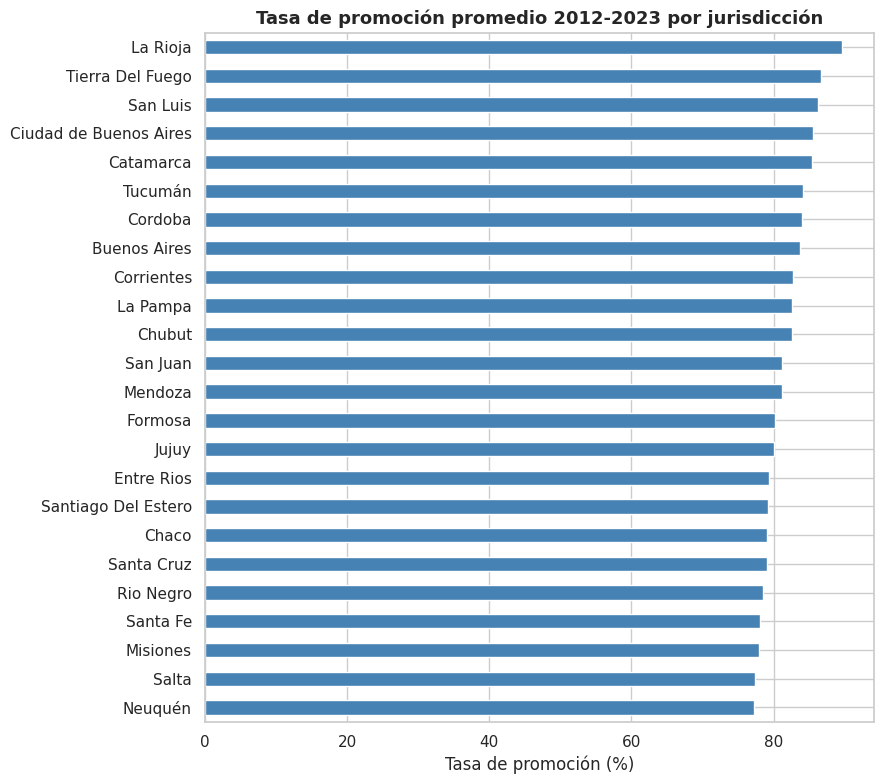

In [8]:
ranking = df_prov.groupby(COL_PROV)['Secundaria - Total'].mean().sort_values()
plt.figure(figsize=(9, 8))
ranking.plot(kind='barh', color='#4682b4')
plt.title('Tasa de promoción promedio 2012-2023 por jurisdicción', fontsize=13, fontweight='bold')
plt.xlabel('Tasa de promoción (%)'); plt.ylabel('')
plt.tight_layout(); plt.show()

### 4.6. Correlaciones

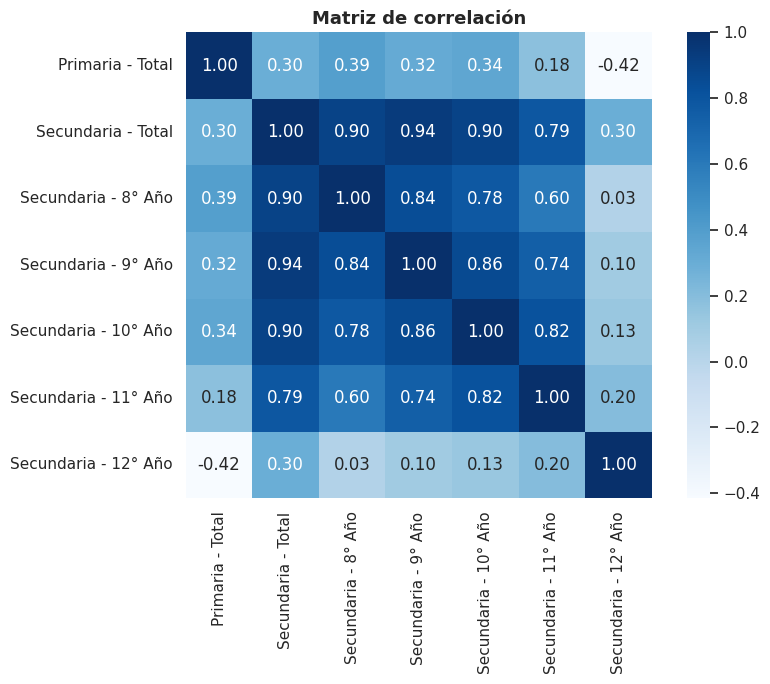

In [9]:
cols_corr = ['Primaria - Total'] + cols_sec
plt.figure(figsize=(9, 7))
sns.heatmap(df_prov[cols_corr].corr(), annot=True, fmt='.2f', cmap='Blues', square=True)
plt.title('Matriz de correlación', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Lectura:** la tasa total de secundaria se asocia fuertemente con 9° año (0,94), 8° y 10° (0,90) y 11° (0,79); 12° año (0,30) y la primaria (0,30) aportan información mucho más independiente. Además, las variables de secundaria están correlacionadas entre sí (multicolinealidad parcial), lo que justifica probar **Ridge**, que estabiliza los coeficientes.

## 5. Construcción de Variables Objetivo y Partición Temporal
- **Regresión:** `Secundaria_Total_Siguiente` = tasa total de secundaria del año $t+1$ de la misma jurisdicción.
- **Clasificación:** `Sube` = 1 si la tasa en $t+1$ es mayor que en $t$, 0 en caso contrario.
- **Features:** las 6 tasas de secundaria del año $t$ + la estructura educativa (6-6 / 7-5).
- **Partición temporal estricta:** *train* con $t$ ∈ [2012, 2018] y *test* con $t$ ∈ [2019, 2022]. No se mezclan filas del futuro en el entrenamiento.

In [10]:
df_prov['Secundaria_Total_Siguiente'] = df_prov.groupby(COL_PROV)['Secundaria - Total'].shift(-1)
df_modelo = df_prov.dropna(subset=['Secundaria_Total_Siguiente']).copy()   # se pierde 2023 (sin t+1)
df_modelo['Sube'] = (df_modelo['Secundaria_Total_Siguiente'] > df_modelo['Secundaria - Total']).astype(int)
df_modelo['Cambio'] = df_modelo['Secundaria_Total_Siguiente'] - df_modelo['Secundaria - Total']

# Ordenado por año para respetar el orden temporal en la validación cruzada
df_modelo = df_modelo.sort_values(['Año', COL_PROV]).reset_index(drop=True)

caracteristicas = cols_sec + ['Estructura_7-5']

train = df_modelo[df_modelo['Año'] <= 2018].reset_index(drop=True)
test = df_modelo[df_modelo['Año'] > 2018].reset_index(drop=True)

X_train, X_test = train[caracteristicas], test[caracteristicas]
y_train_reg, y_test_reg = train['Secundaria_Total_Siguiente'], test['Secundaria_Total_Siguiente']
y_train_clf, y_test_clf = train['Sube'], test['Sube']

print(f'Train: {len(train)} obs. (t = 2012-2018)  |  Test: {len(test)} obs. (t = 2019-2022)')
print(f'% "Sube" en train: {y_train_clf.mean():.1%}  |  en test: {y_test_clf.mean():.1%}')

Train: 168 obs. (t = 2012-2018)  |  Test: 96 obs. (t = 2019-2022)
% "Sube" en train: 64.3%  |  en test: 44.8%


### 5.1. Distribución del cambio interanual (t → t+1)

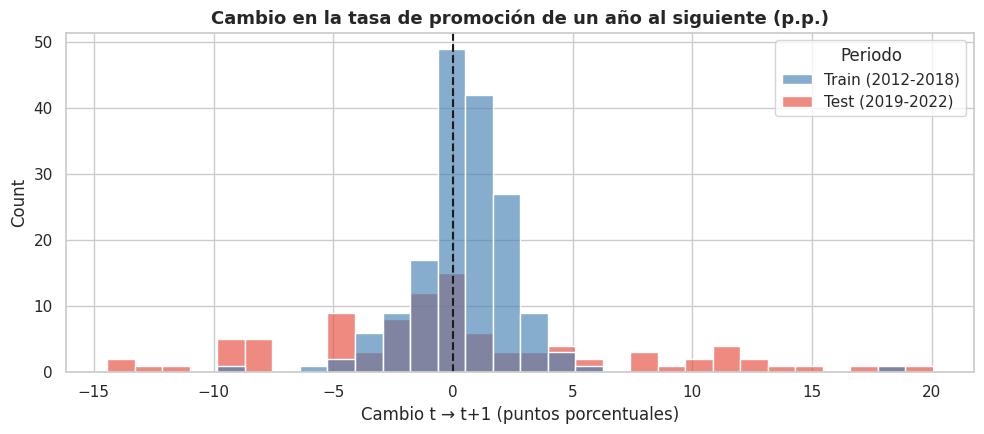

Cambio medio y proporción que sube, según el año t:
Año     2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022
Cambio -0.38  0.22  0.27 -0.89  0.94  1.46  1.82   9.4 -6.61 -1.00 -0.20
Sube    0.67  0.58  0.42  0.21  0.79  0.92  0.92   1.0  0.12  0.25  0.42


In [11]:
plt.figure(figsize=(10, 4.5))
sns.histplot(data=df_modelo.assign(Periodo=np.where(df_modelo['Año'] <= 2018, 'Train (2012-2018)', 'Test (2019-2022)')),
             x='Cambio', hue='Periodo', bins=30, palette=['#4682b4', '#e74c3c'], alpha=0.65)
plt.axvline(0, color='k', linestyle='--')
plt.title('Cambio en la tasa de promoción de un año al siguiente (p.p.)', fontsize=13, fontweight='bold')
plt.xlabel('Cambio t → t+1 (puntos porcentuales)')
plt.tight_layout(); plt.show()

print('Cambio medio y proporción que sube, según el año t:')
print(df_modelo.groupby('Año')[['Cambio', 'Sube']].mean().round(2).T)

**Lectura:** entre 2012 y 2018 el cambio medio anual fue pequeño (de −0,9 a +1,8 p.p.) y la tasa subió en el 64% de los casos. En cambio, para $t$ = 2019 (predecir 2020) el cambio medio fue de **+9,4 p.p.** y para $t$ = 2020 de **−6,6 p.p.**: son movimientos que el modelo nunca vio en *train*. Por eso la proporción de casos que "sube" cae a 45% en *test* (26% si se excluye el año del shock). Esto es un cambio de régimen (*data drift*) y condiciona la interpretación de todas las métricas.

## 6. Validación Cruzada Temporal
Una validación cruzada aleatoria mezclaría pasado y futuro. Por eso usamos una validación **por años (*expanding window*)**: se entrena con los años anteriores a $Y$ y se valida en el año $Y$, para $Y$ = 2014, ..., 2018. Es como estudiar con los exámenes viejos y rendir el del año que viene.

In [12]:
anos_val = [2014, 2015, 2016, 2017, 2018]
cv_anual = [(np.where(train['Año'] < y)[0], np.where(train['Año'] == y)[0]) for y in anos_val]

for (tr_i, va_i), y in zip(cv_anual, anos_val):
    print(f'Fold validación {y}: train={len(tr_i)} obs. | validación={len(va_i)} obs.')

Fold validación 2014: train=48 obs. | validación=24 obs.
Fold validación 2015: train=72 obs. | validación=24 obs.
Fold validación 2016: train=96 obs. | validación=24 obs.
Fold validación 2017: train=120 obs. | validación=24 obs.
Fold validación 2018: train=144 obs. | validación=24 obs.


## 7. Modelos de Regresión
Se comparan:
- **Baseline 1 – Media:** siempre predice el promedio de *train*.
- **Baseline 2 – Persistencia:** "el año que viene será igual que este año".
- **Regresión Lineal Múltiple.**
- **Ridge:** regresión lineal con penalización (`alpha`) que frena el sobreajuste.
- **Random Forest Regressor:** hiperparámetros `max_depth`, `n_estimators`, `min_samples_leaf`.

Los hiperparámetros se optimizan con `GridSearchCV` minimizando el **MAE** en la validación cruzada temporal.

In [13]:
def metricas_reg(y, pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)),
            'R2': r2_score(y, pred)}

modelos_reg = {
    'Regresión Lineal': (LinearRegression(), {}),
    'Ridge': (Pipeline([('sc', StandardScaler()), ('reg', Ridge())]),
              {'reg__alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Random Forest': (RandomForestRegressor(random_state=SEED),
                      {'max_depth': [2, 3, 5, None],
                       'n_estimators': [100, 300],
                       'min_samples_leaf': [1, 5, 10]}),
}

filas, mejores_reg = [], {}

# Baselines
m = DummyRegressor(strategy='mean').fit(X_train, y_train_reg)
for nombre, p_tr, p_te in [
    ('Baseline: media de train', m.predict(X_train), m.predict(X_test)),
    ('Baseline: persistencia', X_train['Secundaria - Total'], X_test['Secundaria - Total'])]:
    mt, ms = metricas_reg(y_train_reg, p_tr), metricas_reg(y_test_reg, p_te)
    filas.append({'Modelo': nombre, 'Hiperparámetros': '-', 'MAE CV': np.nan,
                  'MAE Train': mt['MAE'], 'MAE Test': ms['MAE'],
                  'RMSE Test': ms['RMSE'], 'R² Test': ms['R2']})

# Modelos con búsqueda de hiperparámetros
for nombre, (modelo, grilla) in modelos_reg.items():
    gs = GridSearchCV(modelo, grilla if grilla else {}, cv=cv_anual,
                      scoring='neg_mean_absolute_error', n_jobs=-1)
    gs.fit(X_train, y_train_reg)
    mejor = gs.best_estimator_
    mejores_reg[nombre] = mejor
    mt = metricas_reg(y_train_reg, mejor.predict(X_train))
    ms = metricas_reg(y_test_reg, mejor.predict(X_test))
    filas.append({'Modelo': nombre, 'Hiperparámetros': gs.best_params_ if grilla else '-',
                  'MAE CV': -gs.best_score_, 'MAE Train': mt['MAE'], 'MAE Test': ms['MAE'],
                  'RMSE Test': ms['RMSE'], 'R² Test': ms['R2']})

tabla_reg = pd.DataFrame(filas).set_index('Modelo')
display(tabla_reg.round(3))

,Hiperparámetros,MAE CV,MAE Train,MAE Test,RMSE Test,R² Test
Modelo,,,,,,
Baseline: media de train,-,NaN,3.570,7.055,8.634,-1.583
Baseline: persistencia,-,NaN,1.559,5.048,6.963,-0.680
Regresión Lineal,-,1.705,1.455,4.711,6.509,-0.468
Ridge,{'reg__alpha': 10},1.699,1.493,4.854,6.608,-0.513
Random Forest,"{'max_depth': 3, 'min_samples_leaf': 5, 'n_est...",1.807,1.274,4.296,6.072,-0.278


**Lectura:**
- **Los tres modelos le ganan a los baselines en MAE de test** (Random Forest 4,30; Lineal 4,71; Ridge 4,85, contra 5,05 de la persistencia y 7,06 de la media), pero el R² de test es negativo en todos: el shock de 2020 hace que ningún modelo supere a "predecir el promedio de test".
- **Overfitting:** hay una brecha grande entre *train* (MAE 1,3-1,5) y *test* (4,3-4,9), pero **no es sobreajuste clásico**: el MAE de validación cruzada (1,70-1,81, sobre años "normales") es parecido al de *train*, y la persistencia, que no tiene parámetros que ajustar, también pasa de 1,56 a 5,05. La brecha se explica por el cambio de régimen, no por memorización.
- **Hiperparámetros:** Ridge eligió `alpha = 10` (MAE CV 1,699 vs 1,705 de la lineal: diferencia mínima). Random Forest eligió árboles poco profundos (`max_depth = 3`, `min_samples_leaf = 5`); es el modelo con mayor distancia *train*-CV (1,27 vs 1,81), por eso la grilla lo frenó.

### 7.1. Diagnóstico del mejor modelo de regresión

Mejor modelo de regresión según CV: Ridge


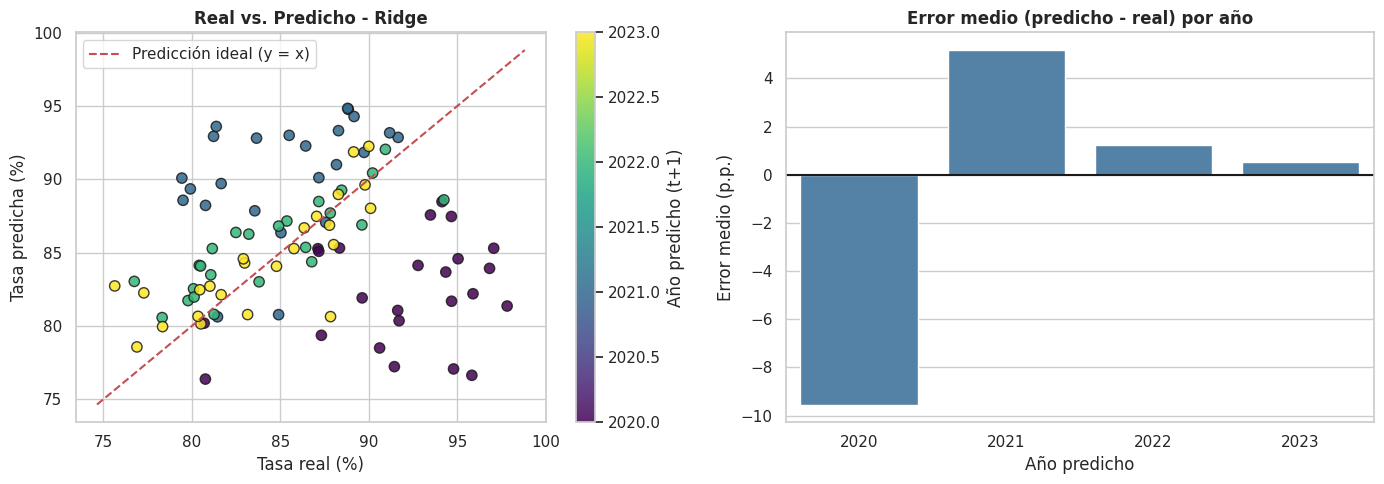

,Real,Predicho,MAE
Año predicho,,,
2020,91.82,82.28,9.54
2021,85.21,90.39,5.63
2022,84.20,85.43,2.33
2023,84.00,84.52,1.92


In [14]:
# Elegimos el modelo con menor MAE de validación cruzada (no el de test, para no filtrar información)
candidatos = tabla_reg.dropna(subset=['MAE CV'])
nombre_reg = candidatos['MAE CV'].idxmin()
modelo_reg = mejores_reg[nombre_reg]
pred_reg = modelo_reg.predict(X_test)
print('Mejor modelo de regresión según CV:', nombre_reg)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Real vs predicho, coloreado por año objetivo (t+1)
sc = ax[0].scatter(y_test_reg, pred_reg, c=test['Año'] + 1, cmap='viridis', s=55, edgecolor='k', alpha=0.85)
lim = [min(y_test_reg.min(), pred_reg.min()) - 1, max(y_test_reg.max(), pred_reg.max()) + 1]
ax[0].plot(lim, lim, 'r--', label='Predicción ideal (y = x)')
ax[0].set_xlabel('Tasa real (%)'); ax[0].set_ylabel('Tasa predicha (%)')
ax[0].set_title(f'Real vs. Predicho - {nombre_reg}', fontweight='bold')
ax[0].legend(); plt.colorbar(sc, ax=ax[0], label='Año predicho (t+1)')

# Error medio por año predicho
err = pd.DataFrame({'Año predicho': test['Año'] + 1, 'Error': pred_reg - y_test_reg.values})
sns.barplot(data=err, x='Año predicho', y='Error', errorbar=None, color='#4682b4', ax=ax[1])
ax[1].axhline(0, color='k')
ax[1].set_title('Error medio (predicho - real) por año', fontweight='bold')
ax[1].set_ylabel('Error medio (p.p.)')
plt.tight_layout(); plt.show()

por_anio = pd.DataFrame({'Año predicho': test['Año'] + 1, 'Real': y_test_reg.values, 'Predicho': pred_reg})
resumen = por_anio.groupby('Año predicho').agg(Real=('Real', 'mean'), Predicho=('Predicho', 'mean'))
resumen['MAE'] = por_anio.assign(e=(por_anio.Real - por_anio.Predicho).abs()).groupby('Año predicho')['e'].mean()
display(resumen.round(2))

**Lectura (modelo elegido por CV: Ridge):**
- En **2020** el error es enorme (real 91,8% vs predicho 82,3%, MAE 9,5 p.p.): un cambio normativo no se puede anticipar con las tasas de los años anteriores.
- En **2021** el modelo *sobreestima* (predice 90,4% vs real 85,2%) porque recibe como entrada las tasas infladas de 2020 y las extrapola.
- En **2022 y 2023**, cuando el sistema se estabiliza, el error baja a 2,3 y 1,9 p.p.

### 7.2. Sensibilidad: ¿qué pasa si dejamos afuera el año del shock (predicción de 2020)?
La fila `t = 2019` predice 2020, el año en que la promoción se disparó por las flexibilizaciones de la pandemia. Medimos de nuevo los modelos **sin esa fila** para separar el error por el shock del error del modelo en años 'normales'.

In [15]:
mask = (test['Año'] >= 2020).values   # filas que predicen 2021, 2022 y 2023
mean_train = y_train_reg.mean()

filas = [
    {'Modelo': 'Baseline: media de train',
     'MAE Test completo': mean_absolute_error(y_test_reg, np.full(len(y_test_reg), mean_train)),
     'MAE Test sin 2020': mean_absolute_error(y_test_reg[mask], np.full(mask.sum(), mean_train)),
     'R² Test sin 2020': r2_score(y_test_reg[mask], np.full(mask.sum(), mean_train))},
    {'Modelo': 'Baseline: persistencia',
     'MAE Test completo': mean_absolute_error(y_test_reg, X_test['Secundaria - Total']),
     'MAE Test sin 2020': mean_absolute_error(y_test_reg[mask], X_test['Secundaria - Total'][mask]),
     'R² Test sin 2020': r2_score(y_test_reg[mask], X_test['Secundaria - Total'][mask])},
]
for nombre, mod in mejores_reg.items():
    p = mod.predict(X_test)
    filas.append({'Modelo': nombre,
                  'MAE Test completo': mean_absolute_error(y_test_reg, p),
                  'MAE Test sin 2020': mean_absolute_error(y_test_reg[mask], p[mask]),
                  'R² Test sin 2020': r2_score(y_test_reg[mask], p[mask])})
display(pd.DataFrame(filas).set_index('Modelo').round(3))

,MAE Test completo,MAE Test sin 2020,R² Test sin 2020
Modelo,,,
Baseline: media de train,7.055,5.317,-1.343
Baseline: persistencia,5.048,3.599,-0.435
Regresión Lineal,4.711,3.127,-0.020
Ridge,4.854,3.293,-0.090
Random Forest,4.296,2.586,0.375


**Lectura:** al excluir la fila que predice 2020, todos los errores bajan y el orden se mantiene: **Random Forest (MAE 2,59; R² 0,38)** < Lineal (3,13) < Ridge (3,29) < persistencia (3,60) < media (5,32). Random Forest es el único con R² positivo; una posible explicación es que captura relaciones no lineales (por ejemplo, la "vuelta a la normalidad" de las jurisdicciones con tasas anormalmente altas tras 2020), algo que los modelos lineales no pueden representar.

## 8. Modelos de Clasificación: ¿la tasa de promoción sube o no sube?
Se compara un **baseline** (clase más frecuente), **Regresión Logística** (hiperparámetro `C`: a menor valor, mayor regularización) y **Random Forest** (`max_depth`, `n_estimators`, `min_samples_leaf`). Se optimiza el **F1** con la misma validación cruzada temporal.

In [16]:
modelos_clf = {
    'Baseline (clase mayoritaria)': (DummyClassifier(strategy='most_frequent'), {}),
    'Regresión Logística': (Pipeline([('sc', StandardScaler()),
                                      ('clf', LogisticRegression(max_iter=1000))]),
                            {'clf__C': [0.01, 0.1, 1, 10, 100]}),
    'Random Forest': (RandomForestClassifier(random_state=SEED),
                      {'max_depth': [2, 3, 5, None],
                       'n_estimators': [100, 300],
                       'min_samples_leaf': [1, 5, 10]}),
}

filas, mejores_clf = [], {}
for nombre, (modelo, grilla) in modelos_clf.items():
    if grilla:
        gs = GridSearchCV(modelo, grilla, cv=cv_anual, scoring='f1', n_jobs=-1).fit(X_train, y_train_clf)
        mejor, cv_f1, params = gs.best_estimator_, gs.best_score_, gs.best_params_
    else:
        mejor, cv_f1, params = modelo.fit(X_train, y_train_clf), np.nan, '-'
    mejores_clf[nombre] = mejor
    p_tr, p_te = mejor.predict(X_train), mejor.predict(X_test)
    filas.append({'Modelo': nombre, 'Hiperparámetros': params, 'F1 CV': cv_f1,
                  'Accuracy Train': accuracy_score(y_train_clf, p_tr),
                  'Accuracy Test': accuracy_score(y_test_clf, p_te),
                  'Precision Test': precision_score(y_test_clf, p_te, zero_division=0),
                  'Recall Test': recall_score(y_test_clf, p_te, zero_division=0),
                  'F1 Test': f1_score(y_test_clf, p_te, zero_division=0)})

tabla_clf = pd.DataFrame(filas).set_index('Modelo')
display(tabla_clf.round(3))

,Hiperparámetros,F1 CV,Accuracy Train,Accuracy Test,Precision Test,Recall Test,F1 Test
Modelo,,,,,,,
Baseline (clase mayoritaria),-,NaN,0.643,0.448,0.448,1.00,0.619
Regresión Logística,{'clf__C': 0.01},0.619,0.643,0.594,0.524,1.00,0.688
Random Forest,"{'max_depth': 2, 'min_samples_leaf': 10, 'n_es...",0.613,0.679,0.500,0.471,0.93,0.625


**Lectura:**
- La grilla eligió los modelos **más simples posibles**: `C = 0,01` (máxima regularización) en la logística y `max_depth = 2` con `min_samples_leaf = 10` en el bosque. Es una señal de que las tasas de secundaria **tienen poca información para anticipar si la tasa sube o baja**.
- Regresión Logística: accuracy de test 0,594 y F1 0,688, contra 0,448 y 0,619 del baseline. Random Forest: 0,500 y 0,625, es decir, casi igual al baseline.
- En *train* la logística tiene accuracy 0,643, igual al porcentaje de casos que suben: básicamente aprendió la tasa base ("tiende a subir"). El Random Forest muestra más brecha *train*-*test* (0,679 vs 0,500).

### 8.1. Matrices de confusión e importancia de variables

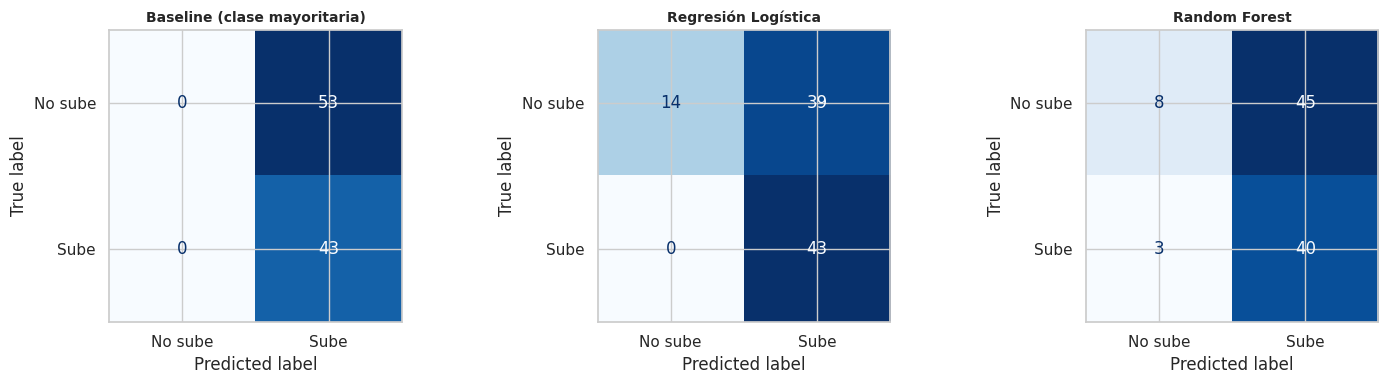

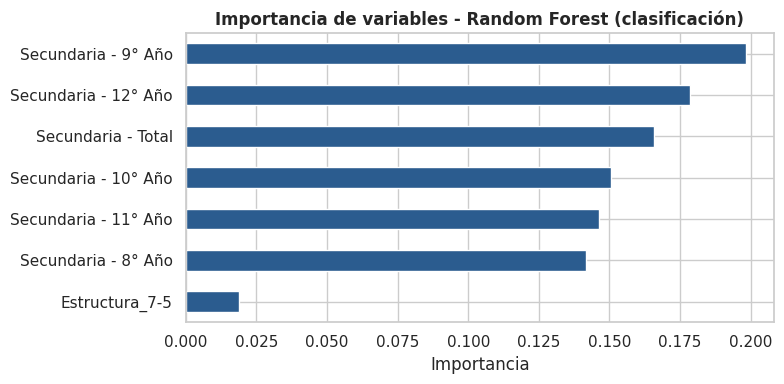

Mejor modelo de clasificación según F1 de CV: Regresión Logística


,Acierto,% real que sube
Año predicho,,
2020,1.00,1.00
2021,0.62,0.12
2022,0.25,0.25
2023,0.50,0.42


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, mejor) in zip(axes, mejores_clf.items()):
    ConfusionMatrixDisplay.from_estimator(mejor, X_test, y_test_clf, display_labels=['No sube', 'Sube'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre, fontweight='bold', fontsize=10)
plt.tight_layout(); plt.show()

rf = mejores_clf['Random Forest']
imp = pd.Series(rf.feature_importances_, index=caracteristicas).sort_values()
plt.figure(figsize=(8, 4))
imp.plot(kind='barh', color='#2b5c8f')
plt.title('Importancia de variables - Random Forest (clasificación)', fontweight='bold')
plt.xlabel('Importancia'); plt.tight_layout(); plt.show()

# Accuracy del mejor modelo según el año predicho
nombre_clf = tabla_clf.dropna(subset=['F1 CV'])['F1 CV'].idxmax()
pred_clf = mejores_clf[nombre_clf].predict(X_test)
acc_anio = pd.DataFrame({'Año predicho': test['Año'] + 1, 'Acierto': (pred_clf == y_test_clf.values).astype(int),
                         '% real que sube': y_test_clf.values}).groupby('Año predicho').mean()
print('Mejor modelo de clasificación según F1 de CV:', nombre_clf)
display(acc_anio.round(2))

**Lectura:**
- **Matrices de confusión:** la logística acierta los 43 casos que suben, pero solo 14 de 53 que no suben; el Random Forest acierta 40 de 43 y 8 de 53. Ambos tienen un sesgo marcado a predecir "sube" (recall ≈ 1), heredado de que en *train* el 64% subía.
- **Por año:** en 2020 el acierto es 100% porque *todas* las jurisdicciones subieron y el modelo siempre dice "sube"; en 2021 y 2022 no logra anticipar las bajas (acierto de 62% y 25%).
- **Importancia de variables:** es casi pareja entre las seis tasas (0,14-0,20) y la estructura educativa aporta muy poco (0,02): ninguna variable concentra la señal.

In [18]:
# Sensibilidad: accuracy y F1 sin la fila que predice 2020
filas = []
for nombre, mod in mejores_clf.items():
    p = mod.predict(X_test)
    filas.append({'Modelo': nombre,
                  'Accuracy Test completo': accuracy_score(y_test_clf, p),
                  'Accuracy Test sin 2020': accuracy_score(y_test_clf[mask], p[mask]),
                  'F1 Test sin 2020': f1_score(y_test_clf[mask], p[mask], zero_division=0)})
print(f'% real "Sube" sin 2020: {y_test_clf[mask].mean():.1%}')
display(pd.DataFrame(filas).set_index('Modelo').round(3))

% real "Sube" sin 2020: 26.4%


,Accuracy Test completo,Accuracy Test sin 2020,F1 Test sin 2020
Modelo,,,
Baseline (clase mayoritaria),0.448,0.264,0.418
Regresión Logística,0.594,0.458,0.494
Random Forest,0.500,0.347,0.420


**Lectura:** sin el año del shock, en *test* solo el 26% de los casos sube, y el baseline cae a accuracy 0,264. La logística llega a 0,458 de accuracy y F1 0,494, y el Random Forest a 0,347 y 0,420. Los modelos mejoran al baseline de forma **modesta**: con estas variables, clasificar la *dirección* del cambio es más difícil que estimar su *nivel*.

## 9. Selección de Modelos y Conclusiones Finales

### 9.1. Tabla de decisión

| Tarea | Modelo seleccionado | Criterio |
|---|---|---|
| **Regresión** | **Random Forest** (`max_depth=3`, `min_samples_leaf=5`, `n_estimators=300`) | Menor error en *test* (MAE 4,30; R² −0,28) y en la sensibilidad sin 2020 (MAE 2,59; R² 0,38). |
| **Clasificación** | **Regresión Logística** (`C=0,01`) | Mejor F1 en validación cruzada y en *test* (0,688); más estable que el Random Forest. |

**Aclaración sobre la selección en regresión:** por validación cruzada el mejor modelo fue Ridge (MAE CV 1,699 vs 1,807 del Random Forest), pero esa validación solo abarca años estables (2014-2018) y no puede medir el comportamiento ante un cambio de régimen. El *test* es el único conjunto que lo contiene y allí el Random Forest es claramente mejor. Los hiperparámetros se eligieron **solo con validación cruzada**; el *test* se usó únicamente para la comparación final, sin reajustar nada.

### 9.2. Conclusiones

1. **Regresión:** los modelos mejoran a los baselines en MAE (4,30 a 4,85 contra 5,05 de la persistencia), pero el R² de *test* es negativo (−0,28 a −0,51). La causa principal es el **cambio de régimen de la pandemia**: la tasa nacional pasó de ≈ 79% (2012-2018) a 93,7% en 2020. Fuera del año del shock, el mejor modelo logra MAE 2,59 p.p. y R² 0,38.
2. **Overfitting controlado:** se usaron validación cruzada temporal, regularización (`alpha` en Ridge, `C` en la logística) y límites de profundidad en los bosques. La brecha *train*-*test* se debe sobre todo al cambio de régimen y no a memorización, como lo muestra que la persistencia, sin parámetros, sufre la misma caída.
3. **Clasificación:** predecir si la tasa sube o no es considerablemente más difícil: el mejor modelo llega a 59% de accuracy (45% del baseline), pero tiende a predecir siempre "sube" (sesgo heredado de *train*). La importancia de variables es pareja, lo que indica que las tasas por año de estudio no alcanzan para anticipar la *dirección* del cambio.
4. **Hallazgo del AED:** 12° año no se vio afectado por la flexibilización de 2020, mientras que 8° a 11° sí. Después de 2020 la tasa total se estabilizó en un nivel más alto que el previo (≈ 84-85%).

### 9.3. Limitaciones
- Solo hay 288 observaciones (24 jurisdicciones × 12 años) y un único episodio de cambio de régimen, por lo que los resultados de *test* son sensibles a ese evento.
- La validación cruzada temporal tiene pocos pliegues (5 años) y todos son de años estables.
- Las variables usadas son únicamente las tasas de promoción; no hay información socioeconómica, de infraestructura ni de matrícula.

### 9.4. Trabajo futuro
- Incorporar **efectos fijos por provincia** (variables *dummy*) y variables rezagadas (por ejemplo, el cambio de $t-1$ a $t$).
- Sumar variables socioeconómicas y de contexto (pobreza, gasto educativo por alumno, matrícula).
- Entrenar con una **variable indicadora de la pandemia** o con ventanas posteriores a 2021 para que el modelo aprenda el nuevo nivel.
- Probar otros algoritmos (Gradient Boosting) y métricas robustas a *outliers* (por ejemplo, error mediano).